# ZD3D — Training and Evaluation

Level-set PINN for 3D linear transport of a **Zalesak slotted sphere**: a
sphere of radius 0.15 with a rectangular slot of half-extents
(0.025, 0.125, 0.10), carried by solid-body rotation about the vertical axis
through (0.5, 0.5). One full revolution completes at t = T = 2*pi, so the shape
returns to its starting position and the error at t=T measures accumulated
drift over a closed orbit.

The slot has **finite depth in z**, so it is a blind pocket: a section near the
pole shows an unbroken sphere while a section through the middle shows the
notch. Fig. D (cutaway) makes this visible.

**Note on the exact solution.** The initial field is the CSG difference
`max(phi_sphere, -phi_slot)`, which is *not* an exact signed-distance function
near the slot's reentrant edges — it returns the distance to the nearer face
rather than to the edge. So `|grad phi| != 1` there in the exact solution, and
the eikonal term genuinely competes with the initial-condition term in those
neighbourhoods. This is why this benchmark wants a far smaller eikonal weight
than the plain-sphere cases.

**Runtime:** longer than the sphere benchmarks — Fourier features, RAD/RAR
resampling, and causal weighting all add per-iteration cost. Measure your first
run and update `EST_MIN_PER_RUN` in the ablation notebook.

**If `ZD3D_pretrained.pth` is present, training is skipped** and the notebook
goes straight to evaluation and figures.

**Outputs:** metrics table, `zd3d_interface.pdf`, `zd3d_verification.pdf`,
`zd3d_growth.pdf`, `zd3d_loss_history.pdf`, `zd3d_cutaway.pdf`, and one row appended to
`ZD3D_results.csv`.

All definitions live in `zd3d_core.py`, shared with
`01_eikonal_ablation.ipynb`.

In [1]:
# --- setup -------------------------------------------------------------
# Put zd3d_core.py in the same Drive folder as this notebook.
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/ZD3D'
except ImportError:
    PROJECT_DIR = os.getcwd()

sys.path.insert(0, PROJECT_DIR)
os.makedirs(PROJECT_DIR, exist_ok=True)

import numpy as np
import torch
import zd3d_core as core

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device,
      '|', torch.cuda.get_device_name(0) if device == 'cuda' else '')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | Tesla T4


## Configuration

Everything tunable lives here. `W_EIK` is the value selected by
`01_eikonal_ablation.ipynb`.

In [2]:
# --- configuration -----------------------------------------------------
W_EIK        = 0.001        # <-- selected by the ablation notebook
W_PDE, W_IC  = 1.0, 10.0

SEED         = 42
N_F, N_I     = 20000, 10000
LAYERS, NEURONS = 8, 256
N_FOURIER, B_SCALE = 128, 5.0
T_FINAL      = 2 * np.pi    # one full revolution
ADAM_EPOCHS  = 20000
LBFGS_EPOCHS = 500
GRID_N       = 201          # dx = 0.005; x=0.5, y=0.75, z=0.5 land on grid points
N_SNAPSHOTS  = 6

# causal weighting (Wang et al. 2022)
M_CHUNKS, EPS_CAUSAL = 32, 1.0
# residual-based adaptive sampling / refinement
RAD_FREQ, RAD_CANDIDATES, RAD_K, RAD_C = 1000, 20000, 1.0, 1.0
RAR_FREQ, RAR_CANDIDATES, RAR_ADD      = 1800, 50000, 500

CKPT     = f'{PROJECT_DIR}/ZD3D_weik{W_EIK:g}_seed{SEED}.pth'
PRETRAIN = f'{PROJECT_DIR}/ZD3D_pretrained.pth'
CSV_PATH = f'{PROJECT_DIR}/ZD3D_results.csv'
FIGDIR   = PROJECT_DIR

times, tlabels = core.snapshot_times(T_FINAL, N_SNAPSHOTS)
print('snapshots:', [f'{t:.3f}' for t in times])

snapshots: ['0.000', '1.257', '2.513', '3.770', '5.027', '6.283']


## Train (skipped if a checkpoint exists)

In [3]:
# --- train or load -----------------------------------------------------
model = core.build_model(device, seed=SEED, layers=LAYERS, neurons=NEURONS,
                         n_fourier=N_FOURIER, b_scale=B_SCALE)

load_from = PRETRAIN if os.path.exists(PRETRAIN) else (CKPT if os.path.exists(CKPT) else None)

if load_from:
    ck = torch.load(load_from, map_location=device, weights_only=False)
    model.load_state_dict(ck['model_state_dict'])
    print(f'loaded {os.path.basename(load_from)} — training skipped')
    print(f"  trained with w_eik={ck.get('w_eik', '?')}, "
          f"seed={ck.get('seed', '?')}, time={ck.get('minutes', float('nan')):.1f} min")
else:
    X_f, X_i = core.sample_points(N_F, N_I, device, seed=SEED)
    sampler = core.AdaptiveSampler(model, X_f, T_FINAL, device,
                                   rad_freq=RAD_FREQ, rad_candidates=RAD_CANDIDATES,
                                   rad_k=RAD_K, rad_c=RAD_C,
                                   rar_freq=RAR_FREQ, rar_candidates=RAR_CANDIDATES,
                                   rar_add=RAR_ADD)
    loss_fn = core.make_loss(model, sampler, X_i, T_FINAL, W_PDE, W_IC, W_EIK,
                             m_chunks=M_CHUNKS, eps_causal=EPS_CAUSAL)
    ck = core.train(model, loss_fn, sampler=sampler, adam_epochs=ADAM_EPOCHS,
                    lbfgs_epochs=LBFGS_EPOCHS)
    ck.update(model_state_dict=model.state_dict(), w_eik=W_EIK, seed=SEED,
              w_pde=W_PDE, w_ic=W_IC, N_f=N_F, N_i=N_I,
              layers=LAYERS, neurons=NEURONS, n_fourier=N_FOURIER,
              b_scale=B_SCALE, m_chunks=M_CHUNKS, eps_causal=EPS_CAUSAL,
              adam_epochs=ADAM_EPOCHS, lbfgs_epochs=LBFGS_EPOCHS)
    torch.save(ck, CKPT)
    print('saved', CKPT)

loaded ZD3D_weik0.001_seed42.pth — training skipped
  trained with w_eik=0.001, seed=42, time=24.9 min


## Evaluate

Metrics on a 201³ grid at six snapshots.

- `abs L2` — sqrt(mean(e²)); equals the discrete L² norm since the domain has unit measure
- `rel L2` — standard relative-L₂ PINN convention
- `MAPE` — volume conservation error, V by cell counting
- `eik dev` — mean ‖∇φ̂|−1| in a 3-cell band around the interface

In [4]:
# --- evaluate ----------------------------------------------------------
grid = core.Grid(n=GRID_N)
res = core.evaluate(model, grid, times, T_FINAL, device, cache=True)
core.print_metrics(times, res)


Snapshot          abs L2   rel L2 (%)      vol abs    MAPE (%)      eik dev
---------------------------------------------------------------------------
t=0.000         4.71e-04       0.112%     7.29e-05      0.619%     8.82e-02
t=1.257         1.22e-03       0.289%     1.82e-05      0.155%     9.47e-02
t=2.513         1.47e-03       0.348%     1.31e-05      0.111%     9.72e-02
t=3.770         2.22e-03       0.526%     6.76e-05      0.574%     1.03e-01
t=5.027         2.96e-03       0.701%     2.79e-05      0.237%     1.11e-01
t=6.283         3.83e-03       0.907%     3.21e-05      0.273%     1.18e-01
---------------------------------------------------------------------------
avg             2.03e-03       0.480%     3.86e-05      0.328%     1.02e-01

Snapshot       slot filled (%)   solid eroded (%)
-------------------------------------------------
t=0.000                13.046%             3.401%
t=1.257                17.483%             3.296%
t=2.513                20.002%        

## Figures

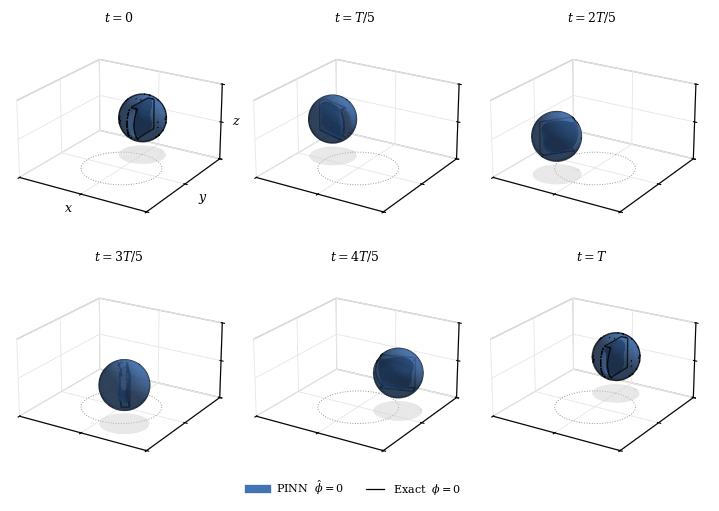

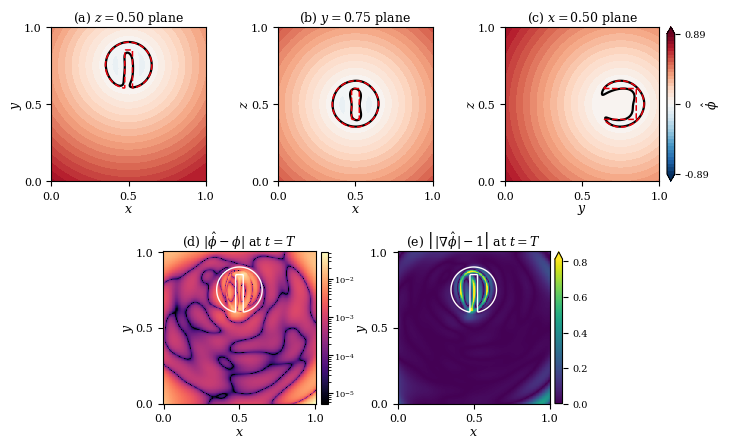

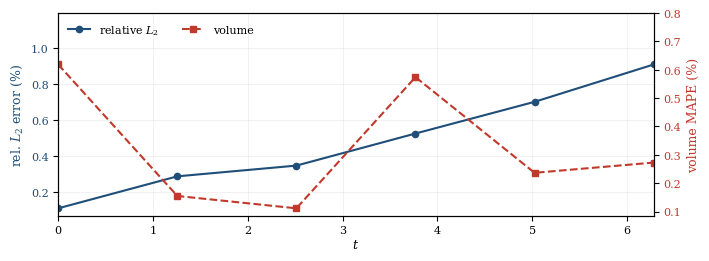

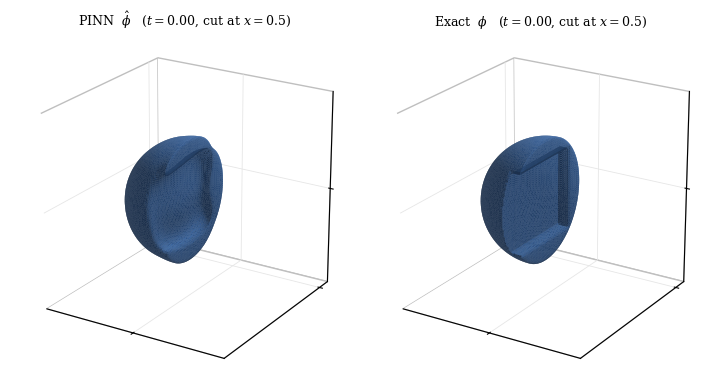

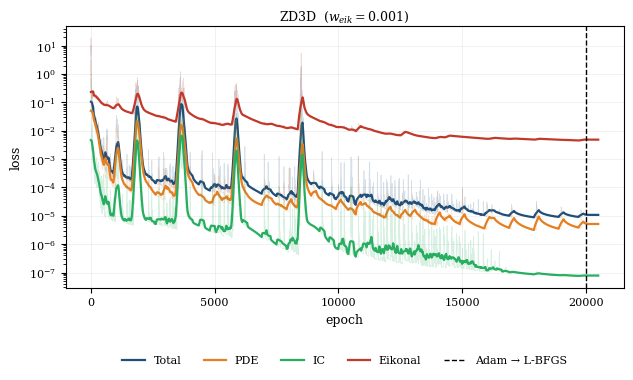

In [5]:
# --- figures -----------------------------------------------------------
import matplotlib.pyplot as plt

core.figure_interface(grid, times, tlabels, res['PHI_P'], res['PHI_E'],
                      savepath=f'{FIGDIR}/zd3d_interface')
plt.show()

core.figure_verification(grid, times, res, T_FINAL,
                         savepath=f'{FIGDIR}/zd3d_verification',
                         include_growth=False)
plt.show()

core.figure_growth(times, res, savepath=f'{FIGDIR}/zd3d_growth')
plt.show()

# cutaway at x = 0.5: the only view that shows the blind pocket
core.figure_cutaway(grid, res['PHI_P'], res['PHI_E'], times[0],
                    savepath=f'{FIGDIR}/zd3d_cutaway')
plt.show()

if 'history' in ck:
    core.figure_loss_history(ck['history'], ADAM_EPOCHS,
                             rf'ZD3D  ($w_{{eik}}={W_EIK:g}$)',
                             savepath=f'{FIGDIR}/zd3d_loss_history')
    plt.show()
else:
    print('no loss history in this checkpoint — skipping zd3d_loss_history')

## Log the run

In [6]:
# --- append one row ----------------------------------------------------
import csv

row = {'w_eik': W_EIK, 'seed': SEED, 'w_pde': W_PDE, 'w_ic': W_IC,
       'N_f': N_F, 'N_i': N_I, 'layers': LAYERS, 'neurons': NEURONS,
       'adam_epochs': ADAM_EPOCHS, 'lbfgs_epochs': LBFGS_EPOCHS,
       'scheduler': 'CosineAnnealingLR', 'eta_min': 1e-5,
       'grid_n': GRID_N, 't_normalized': True}

for i, t in enumerate(times):
    tag = f't{i}'
    row[f'L2abs_{tag}']  = f"{res['l2_abs'][i]:.3e}"
    row[f'L2rel_{tag}']  = f"{res['rel_L2'][i]:.4f}"
    row[f'volabs_{tag}'] = f"{res['vol_abs'][i]:.3e}"
    row[f'MAPE_{tag}']   = f"{res['vol_MAPE'][i]:.4f}"
    row[f'eikdev_{tag}'] = f"{res['eik_dev'][i]:.3e}"

row.update({'avg_L2abs':  f"{res['avg_l2_abs']:.3e}",
            'avg_L2rel':  f"{res['avg_rel_L2']:.4f}",
            'avg_volabs': f"{res['avg_vol_abs']:.3e}",
            'avg_MAPE':   f"{res['avg_vol_MAPE']:.4f}",
            'avg_eikdev': f"{res['avg_eik_dev']:.3e}",
            'minutes':    f"{ck.get('minutes', float('nan')):.2f}",
            'lbfgs_gain': f"{ck.get('lbfgs_gain', float('nan')):.3e}"})

new = not os.path.exists(CSV_PATH) or os.path.getsize(CSV_PATH) == 0
with open(CSV_PATH, 'a', newline='') as f:
    w = csv.DictWriter(f, fieldnames=list(row))
    if new:
        w.writeheader()
    w.writerow(row)
print('row appended →', CSV_PATH)

row appended → /content/drive/MyDrive/ZD3D/ZD3D_results.csv
